# Exploratory data analysis

## 1. Target analysis (isFraud column)

### Objective
Visually confirm the two properties that underpin the entire modeling process:
1. The **extreme imbalance** between the classes (3.5% fraud).
2. The **asymmetry in the distribution** of `TransactionAmt` and the
   *card testing* pattern (p25 values are lower for fraud transactions than for non-fraud transactions).

### Conditional downstream decisions
- **Primary metric**: AUC-PR (not AUC-ROC, which is misleading at 3.5%).
- **Weighting strategy**: `class_weight=‘balanced’` for linear models,
  `scale_pos_weight` for XGBoost, native parameter for LightGBM.
- **`TransactionAmt` transformation**: log1p for linear models, none for trees.
- **Candidate features**: `is_micro_amount` to capture card testing.

In [0]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Defining the style
plt.rcParams.update({
    "figure.dpi": 100,
    "figure.figsize": (8, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

TABLE = "fraud.silver.transactions_clean"

is_fraud,count,pct
0,569877,96.50099908558269
1,20663,3.499000914417313


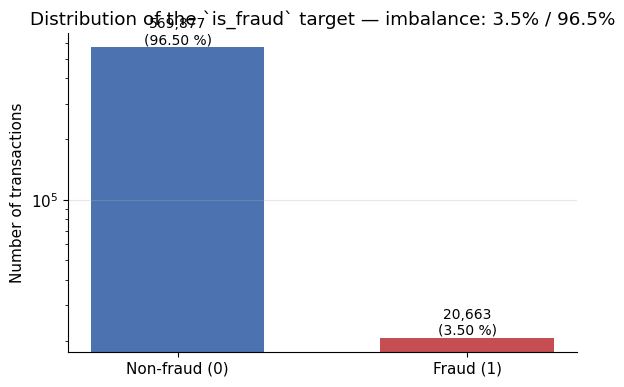

In [0]:
# Gather the dataFrame with spark
target_df = (
    spark.table(TABLE)
         .groupBy("is_fraud")
         .count()
         .orderBy("is_fraud")
         .toPandas()
)
target_df["pct"] = 100.0 * target_df["count"] / target_df["count"].sum()

# Display for trace
display(target_df)

# Graph (bar chart)
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(
    ["Non-fraud (0)", "Fraud (1)"],
    target_df["count"].values,
    color=["#4C72B0", "#C44E52"],
    width=0.6,
)
ax.set_ylabel("Number of transactions")
ax.set_title("Distribution of the `is_fraud` target — imbalance: 3.5% / 96.5%")
ax.set_yscale("log")  # log scale to make the fraud bar visible
ax.grid(axis="x", visible=False)

for bar, count, pct in zip(bars, target_df["count"], target_df["pct"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(),
            f"{count:,}\n({pct:.2f} %)",
            ha="center", va="bottom", fontsize=10)

plt.tight_layout()
plt.show()

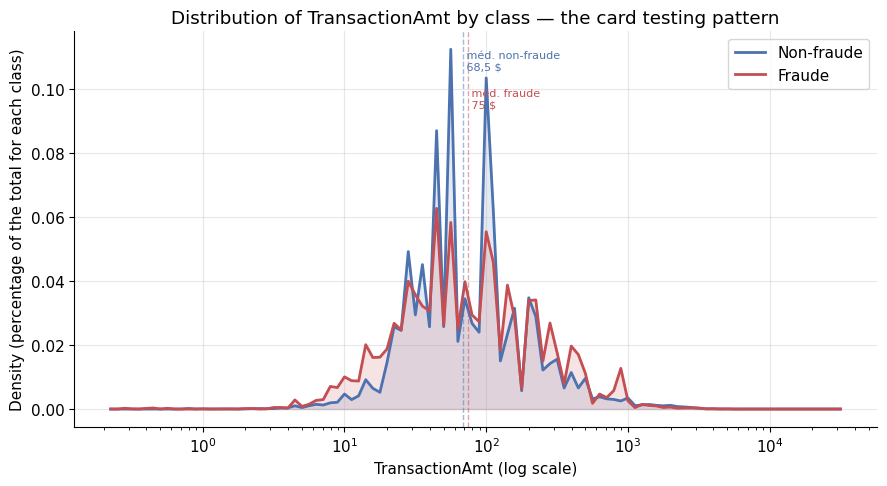

is_fraud,n,min,p25,median,p75,max,moyenne
0,569877,0.25,43.97,68.5,120.0,31937.39,134.51
1,20663,0.29,35.04,75.0,161.0,5191.0,149.24


In [0]:
# TransactionAmt by class (log)
# Log10 bins in Spark, aggregated by class
# floor(log10(amt) * 20) = 20 bins per decade
from pyspark.sql import functions as F

binned = (
    spark.table(TABLE)
         .filter("transaction_amt > 0")
         .withColumn("log_bin", F.floor(F.log10("transaction_amt") * 20))
         .groupBy("log_bin", "is_fraud")
         .count()
         .orderBy("log_bin")
         .toPandas()
)

# Pivot for plotting two series
pivot = binned.pivot(index="log_bin", columns="is_fraud", values="count").fillna(0)
# Convert bin → central value of the bin (in log10)
pivot["amt_center"] = 10 ** (pivot.index / 20.0)

# Approximate density (normalize to compare shapes, not volumes)
pivot["density_0"] = pivot[0] / pivot[0].sum()
pivot["density_1"] = pivot[1] / pivot[1].sum()

# Graphs
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(pivot["amt_center"], pivot["density_0"], label="Non-fraude", color="#4C72B0", lw=2)
ax.plot(pivot["amt_center"], pivot["density_1"], label="Fraude", color="#C44E52", lw=2)
ax.fill_between(pivot["amt_center"], pivot["density_0"], alpha=0.15, color="#4C72B0")
ax.fill_between(pivot["amt_center"], pivot["density_1"], alpha=0.15, color="#C44E52")

ax.set_xscale("log")
ax.set_xlabel("TransactionAmt (log scale)")
ax.set_ylabel("Density (percentage of the total for each class)")
ax.set_title("Distribution of TransactionAmt by class — the card testing pattern")

# Vertical lines at the medians and P25 (from the profiling)
ax.axvline(68.5,  color="#4C72B0", ls="--", alpha=0.5, lw=1)
ax.axvline(75.0,  color="#C44E52", ls="--", alpha=0.5, lw=1)
ax.text(68.5, ax.get_ylim()[1] * 0.95, " méd. non-fraude\n 68,5 $", fontsize=8,
        color="#4C72B0", va="top")
ax.text(75.0, ax.get_ylim()[1] * 0.85, " méd. fraude\n 75 $", fontsize=8,
        color="#C44E52", va="top")

ax.legend()
plt.tight_layout()
plt.show()

#Summary Table for the Trace
summary = (
    spark.table(TABLE)
         .groupBy("is_fraud")
         .agg(
             F.count("*").alias("n"),
             F.round(F.min("transaction_amt"), 2).alias("min"),
             F.round(F.expr("percentile(transaction_amt, 0.25)"), 2).alias("p25"),
             F.round(F.expr("percentile(transaction_amt, 0.50)"), 2).alias("median"),
             F.round(F.expr("percentile(transaction_amt, 0.75)"), 2).alias("p75"),
             F.round(F.max("transaction_amt"), 2).alias("max"),
             F.round(F.avg("transaction_amt"), 2).alias("moyenne"),
         )
         .orderBy("is_fraud")
)
display(summary)

### Interpretation

**Imbalance**:
- Non-fraud: 569,877 (96.50%)
- Fraud: 20,663 (3.50%)
- Ratio: 27.6:1

**Distribution of `TransactionAmt`**:
- Non-fraud: median $68.5 | 25th percentile $44 | maximum $31,937
- Fraud: median $75 | 25th percentile $35 | maximum $5,191

**Two observations**:
1. **Card testing**: The p25 value for fraud (35 $) is *lower* than that for
   non-fraud transactions (44 $). Fraudsters test the card with small amounts
   before carrying out the actual fraud. This pattern is visible on the graph where
   the curves intersect to the left of 50 $.
3. **Max 6× lower**: Transactions > $5,000 are almost all
   legitimate (B2B, premium purchases)—or intercepted upstream.

**Gold Decisions**:
- **AUC-PR** as the primary metric, AUC-ROC as the secondary metric.
- **Weighting**: `scale_pos_weight = 27.6` for XGBoost; native equivalent for LightGBM.
- **Candidate features**:
  - `is_micro_amount` = `transaction_amt < 10` → captures card testing.
  - `log_transaction_amt` = `log1p(transaction_amt)` → useful if using a linear model
    (heavily right-skewed distribution; check skewness in Block 3).
- **No clipping** is necessary for the trees. The maximum non-fraud value ($31,937) is
  an outlier, but LightGBM handles it by bins and is not affected.

## 1.2. Target vs numerical columns

### Univariate Numeric Tests (Mann-Whitney U + rank-biserial)

**Method**: Two-sided Mann-Whitney U test (nonparametric, robust to
skewed distributions) on the 399 numeric features in
`transactions_identity_joined`. Effect size: rank-biserial correlation
`r_rb = 1 − 2U/(n₁·n₀)`, range [−1, 1], 0 = no effect.

In [0]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
import warnings
warnings.filterwarnings("ignore")

TABLE = "fraud.silver.transactions_identity_joined"

df = spark.table(TABLE)
numeric_cols = [
    f.name for f in df.schema.fields
    if str(f.dataType) in ("DoubleType()", "LongType()", "IntegerType()", "FloatType()")
    and f.name not in ("is_fraud", "transaction_id")
]
print(f"{len(numeric_cols)} numeric columns to be tested (excluding 'target' and 'ID')")

399 numeric columns to be tested (excluding “target” and “ID”)


In [0]:
# Implementing the Mann-Whitney U test+ Rank-Biserial to have the strenght of the relation between the feature and the target
pdf = (spark.table(TABLE)
       .select(["is_fraud"] + numeric_cols)
       .toPandas())

y = pdf["is_fraud"].values.astype(np.int8)
n_pos = int((y == 1).sum())
n_neg = int((y == 0).sum())
print(f"Frauds : {n_pos:,} | Non-frauds : {n_neg:,}")

results = []
for col in numeric_cols:
    x = pdf[col].values
    mask = ~np.isnan(x)
    x_clean = x[mask]
    y_clean = y[mask]
    
    n_non_null = len(x_clean)
    n_fraud_non_null = int((y_clean == 1).sum())
    n_nonfraud_non_null = int((y_clean == 0).sum())
    
    # Constant feature OR not enough data to test
    if len(np.unique(x_clean)) < 2 or n_fraud_non_null < 30 or n_nonfraud_non_null < 30:
        results.append({
            "column": col, "U": np.nan, "p_value": np.nan,
            "r_rb": 0.0, "direction": "insufficient_data",
            "n_null_pct": round(100.0 * (~mask).sum() / len(x), 3),
            "n_non_null": n_non_null,
        })
        continue
    
    U, p = mannwhitneyu(
        x_clean[y_clean == 1], x_clean[y_clean == 0], alternative="two-sided"
    )
    r_rb = 1 - (2 * U) / (n_fraud_non_null * n_nonfraud_non_null)
    
    med_fraud = np.median(x_clean[y_clean == 1])
    med_nonfraud = np.median(x_clean[y_clean == 0])
    direction = "fraud_higher" if med_fraud > med_nonfraud else "fraud_lower"
    
    results.append({
        "column": col, "U": float(U), "p_value": float(p),
        "r_rb": float(r_rb), "direction": direction,
        "n_null_pct": round(100.0 * (~mask).sum() / len(x), 3),
        "n_non_null": n_non_null,
    })

df_numeric_stats = pd.DataFrame(results)
df_numeric_stats["abs_r_rb"] = df_numeric_stats["r_rb"].abs()
df_numeric_stats = df_numeric_stats.sort_values("abs_r_rb", ascending=False).reset_index(drop=True)

print(f"\nTest finished : {len(df_numeric_stats)} features")
display(df_numeric_stats.head(40))

Frauds : 20,663 | Non-frauds : 569,877

Test finished : 399 features


column,U,p_value,r_rb,direction,n_null_pct,n_non_null,abs_r_rb
d5,7.474283475E8,0.0,0.4907885774543196,fraud_lower,52.467,280699,0.4907885774543196
v258,9.133257595E8,0.0,-0.490577439223562,fraud_higher,77.913,130430,0.490577439223562
v218,9.040828155E8,0.0,-0.4754926530395511,fraud_higher,77.913,130430,0.4754926530395511
v219,8.99975723E8,0.0,-0.4687897440745661,fraud_higher,77.913,130430,0.4687897440745661
v264,8.955029505E8,0.0,-0.46149003341828343,fraud_higher,77.913,130430,0.46149003341828343
v257,8.92030502E8,0.0,-0.455822884168273,fraud_higher,77.913,130430,0.455822884168273
v265,8.90408475E8,0.0,-0.45317568318126145,fraud_higher,77.913,130430,0.45317568318126145
v217,8.77758139E8,0.0,-0.432529922077884,fraud_higher,77.913,130430,0.432529922077884
v232,8.73265904E8,0.0,-0.4251984479865849,fraud_higher,77.913,130430,0.4251984479865849
v229,8.728651265E8,0.0,-0.42454436603013646,fraud_higher,77.913,130430,0.42454436603013646


In [0]:
print("Distribution of |r_rb| :")
print(f"  |r_rb| > 0.40 (high)     : {(df_numeric_stats['abs_r_rb'] > 0.40).sum():>3}")
print(f"  0.20 – 0.40 (medium)      : {((df_numeric_stats['abs_r_rb'] > 0.20) & (df_numeric_stats['abs_r_rb'] <= 0.40)).sum():>3}")
print(f"  0.10 – 0.20 (low)     : {((df_numeric_stats['abs_r_rb'] > 0.10) & (df_numeric_stats['abs_r_rb'] <= 0.20)).sum():>3}")
print(f"  < 0.10 (negligible)     : {(df_numeric_stats['abs_r_rb'] <= 0.10).sum():>3}")
print(f"  insufficient_data        : {(df_numeric_stats['direction'] == 'insufficient_data').sum():>3}")

print(f"\nFeatures with n_non_null < 10 000 :")
print(df_numeric_stats[df_numeric_stats['n_non_null'] < 10_000][['column', 'n_non_null', 'abs_r_rb']].head(20))

# Persistence
spark.createDataFrame(
    df_numeric_stats.drop(columns=["abs_r_rb"])
).write.format("delta").mode("overwrite").saveAsTable("fraud.bronze.eda_numeric_stats")

print("\n Table fraud.bronze.eda_numeric_stats persisted")

Distribution of |r_rb| :
  |r_rb| > 0.40 (gigh)     :  19
  0.20 – 0.40 (medium)      : 120
  0.10 – 0.20 (low)     :  93
  < 0.10 (negligible)     : 167
  insufficient_data        :   0

Features with n_non_null < 10 000 :
    column  n_non_null  abs_r_rb
137  id_07        5155  0.201316
141  id_26        5163  0.192615
204  id_08        5155  0.124926
212  id_22        5169  0.116536
258  id_21        5159  0.074657
275  id_25        5132  0.062250
290  id_24        4747  0.052275

 Table fraud.bronze.eda_numeric_stats persisted


### Results

**232 numerical features** with (|r_rb| > 0.10 out of 399)
**Effect size** :
| Category | N | % |
|---|---|---|
| Strong effect — abs(r_rb) > 0.40 | 19 | 4.8% |
| Moderate effect — 0.20 to 0.40 | 120 | 30.1% |
| Weak effect — 0.10 to 0.20 | 93 | 23.3% |
| Negligible effect — < 0.10 | 167 | 41.9% |
| Insufficient data | 0 | 0% |
| **Total** | **399** | **100%** |

**Top 5 features** :
| Feature | r_rb (abs) | NULL % | Direction |
|---|---|---|---|
| d5 | 0,491 | 52,5 % | fraud_lower |
| v258 | 0,491 | 77,9 % | fraud_higher |
| v218 | 0,475 | 77,9 % | fraud_higher |
| v219 | 0,469 | 77,9 % | fraud_higher |
| v264 | 0,461 | 77,9 % | fraud_higher |

**Key finding**: 14 of the 19 features with `|r_rb| > 0.40` belong
to the **V* block with 77.913% synchronized NULLs** (identified in profiling step 6).
They carry the strongest signal in the dataset. The mechanical rule
"> 50% NULL → drop" would have removed 14 out of 19 of the best features.

**Secondary finding**: the deltas `d2`, `d3`, and `d5` are in `fraud_lower`
— fraudulent transactions have lower values, a hallmark of *card testing*
(short time intervals between successive fraudulent transactions).

**Decision**: retention threshold `|r_rb| > 0.10` → **232 features retained**
(58%). The 167 features with `< 0.10` are candidates for removal, but the
correlation filter (next step) will first reduce the V* cluster.

**Note on identities**: `id_07` (0.201) and `id_26` (0.193) exceed
the threshold but only on ~5,155 non-NULL rows (≈180 fraud cases).
Signal to be confirmed—not to be treated as critical.


## 1.3.Target vs categorical columns

### a — Inventory of Categorical Features

**Objective**: To compile an exhaustive list of the categorical features to be tested,
their raw cardinality, and the grouping rule that will be applied to them.

**Scope**: 37 features — 32 plain text + 5 numeric IDs (`card2/3/5`, `addr1/2`).
`card1` is excluded from the test and documented in `special_handling` (processed via UID in Gold).

**Grouping Rules** :
- card ≤ 20 → `none` (except for values < 0.05% → OTHER)
- 21 ≤ card ≤ 100 → `1-percent-threshold`
- card > 100 → `95-percent-coverage` (95% cumulative coverage)
- `card1` → `special_handling`

**⚠️ Important note about NULL values**: The `null_pct` values calculated below are those from the
**joined** table (`transactions_identity_joined`). For `identity` features,
they are **inflated by the LEFT JOIN**: a transaction without a fingerprint has ALL
identity columns set to NULL. Example: `id_30` is ~46% NULL in `identity_clean`,
but ~87% NULL in `joined`. This is **expected**—
The `missing` result for a feature identity
on `joined` combines two scenarios: “no fingerprint at all” AND “fingerprint
exists but value is missing.” Consequence: the main test on `joined` measures
the total association (both phenomena), while a secondary test on
`identity_clean` will isolate the second one. Both will be generated.

In [0]:
from pyspark.sql import functions as F
import pandas as pd

TABLE = "fraud.silver.transactions_identity_joined"

# The 37 categorical features (excluding card1 → treated as “Gold” via UID)
CATEGORICAL_COLS = [
    # ─── Transactions : Pur text (14) ───
    "product_cd", "card4", "card6", "p_emaildomain", "r_emaildomain",
    "m1", "m2", "m3", "m4", "m5", "m6", "m7", "m8", "m9",
    # ─── Transactions : Numerical IDS (5) ───
    "card2", "card3", "card5", "addr1", "addr2",
    # ─── Identity : Pur text (14) ───
    "device_type", "device_info",
    "id_12", "id_15", "id_16", "id_23", "id_27", "id_28", "id_29",
    "id_34", "id_35", "id_36", "id_37", "id_38",
    # ─── Identity : mid cardinality (3) ───
    "id_30", "id_31", "id_33",
]

df = spark.table(TABLE)
missing = [c for c in CATEGORICAL_COLS if c not in df.columns]
assert not missing, f"Missing columns : {missing}"

# Cast in a string: The 5 numeric IDs must be standardized for future grouping
df_cast = df.select(*[F.col(c).cast("string").alias(c) for c in CATEGORICAL_COLS])
n_total = df_cast.count()

# Cardinality + null_pct in a single pass
agg = []
for c in CATEGORICAL_COLS:
    agg.append(F.countDistinct(F.col(c)).alias(f"card_{c}"))
    agg.append(F.sum(F.when(F.col(c).isNull(), 1).otherwise(0)).alias(f"null_{c}"))
row = df_cast.agg(*agg).collect()[0].asDict()

rows = []
for c in CATEGORICAL_COLS:
    card = row[f"card_{c}"]
    null_pct = round(100.0 * row[f"null_{c}"] / n_total, 3)
    rule = ("none"       if card <= 20 else
            "threshold_1pct" if card <= 100 else
            "cov_95pct")
    rows.append({
        "column_name":       c,
        "n_distinct_raw":    card,
        "null_pct":          null_pct,
        "regroupment_rule": rule,
        "null_test_required": null_pct > 50.0,
    })

inv = pd.DataFrame(rows).sort_values("n_distinct_raw", ascending=False).reset_index(drop=True)

# card1: documentation in special_handling (untested)
inv = pd.concat([inv, pd.DataFrame([{
    "column_name": "card1",
    "n_distinct_raw": None,
    "null_pct": None,
    "regroupment_rule": "special_handling",
    "null_test_required": False,
}])], ignore_index=True)

display(inv)

print(f"{len(inv)} Listed features "
      f"({len(CATEGORICAL_COLS)} tested + card1 in special_handling)")
print(f"\nDistribution of Rules :")
print(inv["regroupment_rule"].value_counts().to_string())
print(f"\nFeatures to test with NULL-only (null_pct > 50%) : "
      f"{int(inv['null_test_required'].sum())}")

# Persistance
spark.createDataFrame(inv).write.format("delta") \
    .mode("overwrite").saveAsTable("fraud.bronze.eda_categorical_inventory")
print("\nfraud.bronze.eda_categorical_inventory persisted")

/home/spark-49718a84-844e-4277-a1ad-e9/.ipykernel/63/command-6715991862850269-2313714451:54: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  inv = pd.concat([inv, pd.DataFrame([{


column_name,n_distinct_raw,null_pct,regroupment_rule,null_test_required
device_info,1779,79.906,cov_95pct,true
card2,500,1.513,cov_95pct,false
addr1,332,11.126,cov_95pct,false
id_33,260,87.589,cov_95pct,true
id_31,130,76.245,cov_95pct,true
card5,119,0.721,cov_95pct,false
card3,114,0.265,cov_95pct,false
id_30,75,86.865,threshold_1pct,true
addr2,74,11.126,threshold_1pct,false
r_emaildomain,60,76.752,threshold_1pct,true


37 Listed features (36 tested + card1 in special_handling)

Distribution of Rules :
regroupment_rule
none                25
cov_95pct            7
threshold_1pct       4
special_handling     1

Features to test with NULL-only (null_pct > 50%) : 22

fraud.bronze.eda_categorical_inventory persisted


### Results: Inventory

**Final scope**: 36 features tested + `card1` in `special_handling` = 37 features.

**Breakdown by clustering rule**:
| Rule | N | Features |
|---|---|---|
| `none` (card ≤ 20) | 25 | `ProductCD`, `card4`, `card6`, `M1-M9`, `card3`, `card5`, `device_type`, `id_12/15/16/23/27/28/29/34-38` |
| `1-percent-threshold` (21–100) | 4 | `P_emaildomain`, `R_emaildomain`, `addr2`, `id_30` |
| `95th percentile` (> 100) | 7 | `card2`, `addr1`, `device_info`, `id_31`, `id_33`, + 2 |
| `special_handling` | 1 | `card1` (13,500 values → Gold via UID) |

**22 features require a NULL-only test** (`null_pct > 50%`):
- The 15 `id_*` identity strings (`id_12` through `id_38`, excluding the numeric `id_32`)
- 7 `M*` (`M1, M2, M3, M5, M7, M8, M9`)
- `device_info`, `device_type`

**Critical finding**: The `null_pct` for these features is **inflated by the LEFT JOIN**. Example: `id_30` is ~46% NULL in `identity_clean`, but ~87% in `joined` (because 76% of transactions have no fingerprint). The main test on `joined` will measure the **total** association (fingerprint + value), which is **redundant** among the 15 identity features. The secondary test on `identity_clean` (sub-section 2.4) will isolate the signal **specific** to each feature from among the lines that have a fingerprint. The two tests are complementary, not redundant.

**Note on `card1`**: Excluded from the categorical test. Its value will be used in Gold via UID-based aggregations (`card1 + addr1 + D1`), as in the winning contest entry. Documenting this in `special_handling` prevents an unstable Cramér's V across 13,500 categories.


### b-Grouping categorical columns based on our rules and managing missing values for chi squared test

In [0]:
# Regroupment function
def regroup(pdf, col, rule, min_count_none=10, max_cats_cov=50):
    rule_norm = {
        "seuil_1pct": "seuil_1pct",
        "threshold_1pct": "seuil_1pct",
        "cov_95pct": "cov_95pct",
        "coverage_95pct": "cov_95pct",
        "none": "none",
    }.get(rule, rule)
    
    s = pdf[col].astype("object").copy()
    s = s.where(s.notna(), "missing")
    
    non_missing = s[s != "missing"]
    freq = non_missing.value_counts()
    
    if rule_norm == "none":
        to_other = freq[freq < min_count_none].index
    elif rule_norm == "seuil_1pct":
        to_other = freq[freq < 0.01 * len(non_missing)].index
    elif rule_norm == "cov_95pct":
        cum = freq.cumsum() / len(non_missing)
        n_keep = min(int((cum <= 0.95).sum()) + 1, max_cats_cov)
        to_other = freq.index.difference(freq.index[:n_keep])
    else:
        to_other = []
    
    return s.where(~s.isin(to_other), "other")

In [0]:
import pandas as pd

# Loading uniquely important columns
cols_needed = ["is_fraud"] + [c for c in inv["column_name"] if c != "card1"]
pdf = spark.table(TABLE).select(*cols_needed).toPandas()

# Cast ID numerical IDs in string
for c in ["card2", "card3", "card5", "addr1", "addr2"]:
    pdf[c] = pdf[c].astype("object")

# Applying regroupment rules to columns
pdf_grouped = pdf.copy()
for _, row in inv[inv["column_name"] != "card1"].iterrows():
    pdf_grouped[row["column_name"]] = regroup(pdf, row["column_name"], row["regroupment_rule"])

print(f"{len(cols_needed) - 1} features regrouped")

36 features regrouped


In [0]:
# Verification
check = []
for _, row in inv[inv["column_name"] != "card1"].iterrows():
    c = row["column_name"]
    initial = pdf[c].nunique(dropna=False)
    kept = pdf_grouped[c].nunique()
    pct_missing = 100.0 * (pdf_grouped[c] == "missing").mean()
    pct_other = 100.0 * (pdf_grouped[c] == "other").mean()
    check.append({
        "column": c,
        "rule": row["regroupment_rule"],
        "initial": initial,
        "kept": kept,
        "pct_missing": round(pct_missing, 1),
        "pct_other": round(pct_other, 1),
    })

check_df = pd.DataFrame(check).sort_values("kept", ascending=False)
display(check_df)

# Sanity checks
assert not (pdf_grouped.isin(["other"]) & pdf_grouped.isna()).any().any()
print(f"\n {len(check_df)} Grouped features, no residual NaNs")

column,rule,initial,kept,pct_missing,pct_other
device_info,cov_95pct,1780,52,79.9,3.2
card2,cov_95pct,501,52,1.5,20.0
addr1,cov_95pct,333,40,11.1,4.4
id_31,cov_95pct,131,37,76.2,1.2
id_33,cov_95pct,261,29,87.6,0.6
id_30,threshold_1pct,76,22,86.9,1.8
card5,cov_95pct,120,12,0.7,4.6
r_emaildomain,threshold_1pct,61,11,76.8,1.6
p_emaildomain,threshold_1pct,60,10,16.0,6.3
product_cd,none,5,5,0.0,0.0



 36 Grouped features, no residual NaNs


### c-Chi² + Cramér's V

In [0]:
from scipy.stats import chi2_contingency, chi2 as chi2_dist
import numpy as np

global_fraud_rate = pdf_grouped["is_fraud"].mean()
results = []

for _, row in inv[inv["column_name"] != "card1"].iterrows():
    col = row["column_name"]
    s = pdf_grouped[col].astype(str) 
    y = pdf_grouped["is_fraud"]
    
    ct = pd.crosstab(s, y)
    
    if ct.shape[0] < 2:
        results.append({
            "column_name": col, "n_categories_kept": ct.shape[0],
            "chi2_stat": float("nan"), "dof": float("nan"),
            "neg_log10_p": float("nan"),
            "cramers_v": 0.0, "cramers_v_adj": 0.0,
            "null_signal": 0.0, "low_expected_count": True,
            "top_categories": "",
        })
        continue
    
    chi2_stat, p, dof, expected = chi2_contingency(ct)
    n = ct.values.sum()
    k = ct.shape[0]
    r = 2
    
    phi2 = chi2_stat / n
    cramers_v = np.sqrt(phi2 / min(k - 1, r - 1))
    
    phi2_adj = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    cramers_v_adj = np.sqrt(phi2_adj / min(k - 1, r - 1)) if phi2_adj > 0 else 0.0
    
    neg_log10_p = -chi2_dist.logsf(chi2_stat, dof) / np.log(10)
    
    missing_mask = s == "missing"
    null_signal = abs(y[missing_mask].mean() - global_fraud_rate) if missing_mask.sum() > 0 else 0.0
    
    low_expected = bool((expected < 5).any())
    
    cat_stats = pd.DataFrame({
        "n": s.value_counts(),
        "fraud_rate": y.groupby(s).mean(),
    })
    cat_stats = cat_stats[cat_stats["n"] >= 100].sort_values("fraud_rate", ascending=False)
    top_cat_str = " | ".join([
        f"{idx}({r_['fraud_rate']*100:.1f}%,n={int(r_['n'])})"
        for idx, r_ in cat_stats.head(3).iterrows()
    ])
    
    results.append({
        "column_name": col, "n_categories_kept": k,
        "chi2_stat": round(float(chi2_stat), 1),
        "dof": int(dof),
        "neg_log10_p": round(float(neg_log10_p), 2),
        "cramers_v": round(float(cramers_v), 4),
        "cramers_v_adj": round(float(cramers_v_adj), 4),
        "null_signal": round(float(null_signal), 4),
        "low_expected_count": low_expected,
        "top_categories": top_cat_str,
    })

df_cat_stats = pd.DataFrame(results).sort_values("cramers_v_adj", ascending=False).reset_index(drop=True)
display(df_cat_stats)

column_name,n_categories_kept,chi2_stat,dof,neg_log10_p,cramers_v,cramers_v_adj,null_signal,low_expected_count,top_categories
device_info,52,19134.6,51,Infinity,0.18,0.1798,0.0094,true,"hi6210sft build/mra58k(94.7%,n=190) | sm-a300h build/lrx22g(83.3%,n=203) | sm-j320m build/lmy47v(33.3%,n=171)"
id_31,37,18098.0,36,Infinity,0.1751,0.1749,0.0139,false,"firefox(21.8%,n=673) | chrome generic(16.8%,n=4778) | chrome 64.0 for android(15.9%,n=3473)"
r_emaildomain,11,17980.8,10,Infinity,0.1745,0.1744,0.0142,false,"outlook.com(16.5%,n=2507) | icloud.com(12.9%,n=1398) | gmail.com(11.9%,n=57147)"
id_35,3,17183.1,2,Infinity,0.1706,0.1706,0.014,false,"F(12.3%,n=63171) | T(4.5%,n=77814) | missing(2.1%,n=449555)"
card3,4,16963.0,3,Infinity,0.1695,0.1695,0.0101,false,"185.0(13.1%,n=56346) | other(4.0%,n=11342) | missing(2.5%,n=1565)"
product_cd,5,16742.2,4,Infinity,0.1684,0.1684,0.0,false,"c(11.7%,n=68519) | s(5.9%,n=11628) | h(4.8%,n=33024)"
addr2,3,15802.4,2,Infinity,0.1636,0.1636,0.0828,false,"missing(11.8%,n=65706) | other(10.2%,n=4353) | 87.0(2.4%,n=520481)"
addr1,40,15811.4,39,Infinity,0.1636,0.1634,0.0828,false,"missing(11.8%,n=65706) | other(4.2%,n=25876) | 203.0(4.1%,n=3808)"
card2,52,14632.0,51,Infinity,0.1574,0.1571,0.0124,false,"130.0(23.9%,n=2746) | 296.0(19.2%,n=2516) | 500.0(18.1%,n=5045)"
id_15,4,13951.2,3,Infinity,0.1537,0.1537,0.014,false,"Found(10.5%,n=67728) | Unknown(9.2%,n=11645) | New(4.9%,n=61612)"


### d-Final selection of categorical features

**Retention criterion**: `cramers_v > 0.10` (Cohen's "moderate effect" threshold).

**Result**: **22 categorical features retained** out of 36 tested (61%).
The remaining 14 features (Cramér's V ≤ 0.10) are candidates for removal.

**List of the 22 selected features** (sorted by cramers_v_adj in descending order):
| # | Feature | cramers_v_adj | Note |
|---|---|---|---|
| 1 | device_info | 0.1798 | `high_caveat` — low_expected_count (52 categories) |
| 2 | id_31 | 0.1749 | — |
| 3 | r_emaildomain | 0.1744 | — |
| 4 | id_35 | 0.1706 | bloc `id_35-38` (null_signal 0.014) |
| 5 | card3 | 0.1695 | — |
| 6 | product_cd | 0.1684 | — |
| 7 | addr2 | 0.1636 | expected redundancy with `addr1` |
| 8 | addr1 | 0.1634 | expected redundancy with `addr2` |
| 9 | card2 | 0.1571 | — |
| 10 | id_15 | 0.1537 | bloc `id_15/28/29` (null_signal 0.014) |
| 11 | id_29 | 0.1531 | bloc `id_15/28/29` |
| 12 | id_28 | 0.1514 | bloc `id_15/28/29` |
| 13 | m4 | 0.1504 | — |
| 14 | id_16 | 0.1461 | — |
| 15 | id_38 | 0.1451 | bloc `id_35-38` |
| 16 | device_type | 0.1439 | — |
| 17 | id_36 | 0.1385 | bloc `id_35-38` |
| 18 | id_37 | 0.1372 | bloc `id_35-38` |
| 19 | id_12 | 0.1361 | — |
| 20 | m6 | 0.1241 | — |
| 21 | card5 | 0.12 | — |
| 22 | card6 | 0.10 | —|


**Key Findings** :
* **Very narrow range** (0.10–0.18) — no single feature dominates. Vesta’s categorical signal is evenly distributed. As a result, the selection provides little discrimination; it is the **combination** of all 22 features that will make the difference.
- **Fold-safe target encoding** on these 22 features (fit only on the training fold, never on the entire dataset).
- **One-hot encoding** for features with k ≤ 5 — 2 to 5 categories per feature.
- **Target encoding** for features with k > 10 


## 1.4. Correlation analysis between numerical features

In [0]:
# Correlation Matrix + Pair Extraction
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

THRESHOLD_RHO = 0.85
MIN_OBS = 1000

# 1. Retrieve the selected features (|r_rb| > 0.10)
stats = spark.table("fraud.bronze.eda_numeric_stats").toPandas()

# Recalculate abs_r_rb (dropped before persistence)
stats["abs_r_rb"] = stats["r_rb"].abs()

features_kept = stats[stats["abs_r_rb"] > 0.10]["column"].tolist()
print(f"{len(features_kept)} Numerical features selected for the correlation test")

# 2. Sample ~100k
fraction = 100_000 / 590_540
pdf_corr = (spark.table("fraud.silver.transactions_identity_joined")
            .select(features_kept)
            .sample(fraction=fraction, seed=42)
            .toPandas())
print(f"Sample : {len(pdf_corr):,} rows × {len(features_kept)} columns")

# 3. Matrix Spearman
corr_matrix = pdf_corr.corr(method="spearman", min_periods=MIN_OBS)

# 4. Extracting pairs above the threshold (upper triangle)
pairs = []
cols = corr_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        rho = corr_matrix.iloc[i, j]
        if not np.isnan(rho) and abs(rho) > THRESHOLD_RHO:
            pairs.append({
                "feature_1": cols[i],
                "feature_2": cols[j],
                "spearman_rho": round(float(rho), 4),
            })

df_corr_num_num = (pd.DataFrame(pairs)
                   .assign(abs_rho=lambda d: d["spearman_rho"].abs())
                   .sort_values("abs_rho", ascending=False)
                   .reset_index(drop=True))

print(f"\n{len(df_corr_num_num)} pairs above of |ρ| > {THRESHOLD_RHO}")
display(df_corr_num_num.head(30))


232 Numerical features selected for the correlation test
Sample : 99,572 rows × 232 columns

1104 pairs above of |ρ| > 0.85


feature_1,feature_2,spearman_rho,abs_rho
v93,v92,0.9998,0.9998
v15,v16,0.9998,0.9998
v32,v31,0.9998,0.9998
v18,v17,0.9997,0.9997
v22,v21,0.9997,0.9997
v101,v132,0.9995,0.9995
v103,v134,0.9993,0.9993
v316,v293,0.9991,0.9991
v102,v133,0.999,0.999
v318,v295,0.9989,0.9989


In [0]:
#We're going to use NetworkX to transform the list of 
# 1,104 correlated pairs into groups of features that are similar to one another.
from collections import Counter
import networkx as nx

# 1. Degree of each feature (number of pairs in which it appears)
degree = Counter()
for _, r in df_corr_num_num.iterrows():
    degree[r["feature_1"]] += 1
    degree[r["feature_2"]] += 1

degree_df = pd.DataFrame(degree.items(), columns=["feature", "n_pairs"]) \
              .sort_values("n_pairs", ascending=False).reset_index(drop=True)

print("Top 20 features by degree (occurrences in pairs > 0.85) ")
display(degree_df.head(20))

# 2. Breakdown by prefix
def prefix(f):
    for p in ["v", "c", "d", "id_", "card", "addr", "dist", "transaction"]:
        if f.startswith(p):
            return p.rstrip("_") if p.endswith("_") else p
    return "other"

degree_df["prefix"] = degree_df["feature"].apply(prefix)
print("\nBreakdown by prefix :")
print(degree_df.groupby("prefix").agg(
    n_features=("feature", "count"),
    total_pairs=("n_pairs", "sum"),
    mean_degree=("n_pairs", "mean"),
).sort_values("total_pairs", ascending=False))

# 3. Related Components
G = nx.Graph()
G.add_edges_from(df_corr_num_num[["feature_1", "feature_2"]].values.tolist())
components = sorted(nx.connected_components(G), key=len, reverse=True)

print(f"\n{len(components)} Related Components detected")
print(f"Size of the 10 Largest: {[len(c) for c in components[:10]]}")
print(f"Isolated features (no pair > 0.85): {232 - G.number_of_nodes()}")

#  Breakdown of the 5 Largest Components
for i, comp in enumerate(components[:5]):
    prefixes = Counter([prefix(f) for f in comp])
    print(f"\nComponents {i+1} ({len(comp)} features, prefixes : {dict(prefixes)})")
    print(f"  Examples : {sorted(comp)[:8]}{'...' if len(comp) > 8 else ''}")

Top 20 features by degree (occurrences in pairs > 0.85) 


feature,n_pairs
v93,41
v31,41
v92,41
v50,41
v71,41
v72,41
v32,41
v57,40
v51,40
v58,40



Breakdown by prefix :
        n_features  total_pairs  mean_degree
prefix                                      
v              176         2053    11.664773
c                8          144    18.000000
d                5            9     1.800000
id               1            2     2.000000

29 Related Components detected
Size of the 10 Largest: [44, 28, 16, 12, 11, 10, 6, 6, 5, 4]
Isolated features (no pair > 0.85): 42

Components 1 (44 features, prefixes : {'v': 38, 'c': 5, 'id': 1})
  Examples : ['c10', 'c12', 'c4', 'c7', 'c8', 'id_17', 'v15', 'v16']...

Components 2 (28 features, prefixes : {'v': 25, 'd': 3})
  Examples : ['d3', 'd5', 'd7', 'v126', 'v128', 'v167', 'v168', 'v202']...

Components 3 (16 features, prefixes : {'v': 16})
  Examples : ['v180', 'v182', 'v183', 'v184', 'v185', 'v215', 'v216', 'v234']...

Components 4 (12 features, prefixes : {'v': 12})
  Examples : ['v177', 'v178', 'v179', 'v211', 'v212', 'v213', 'v231', 'v232']...

Components 5 (11 features, prefixes : {'

NetworkX grouped **1,104 pairs into 29 clusters** of redundant features, so that we could make a single decision per cluster (keep one, discard the rest) instead of making 1,104 local decisions that would contradict each other.

####  Component-based pruning
##### Pruning Decisions

In [0]:
import networkx as nx
import pandas as pd
import numpy as np

# 1. Loading univariate scores (|r_rb|)
stats = spark.table("fraud.bronze.eda_numeric_stats").toPandas()
stats["abs_r_rb"] = stats["r_rb"].abs()
score_map = dict(zip(stats["column"], stats["abs_r_rb"]))

# 2. Reconstruct the graph from df_corr_num_num (in memory)
G = nx.Graph()
G.add_edges_from(df_corr_num_num[["feature_1", "feature_2"]].values.tolist())
components = sorted(nx.connected_components(G), key=len, reverse=True)

# 3. Pruning : Pruning: 1 survivor per component(best |r_rb|)
decisions = []

for comp_id, comp in enumerate(components, start=1):
    comp_list = sorted(comp, key=lambda f: score_map.get(f, 0), reverse=True)
    survivor = comp_list[0]
    for f in comp_list:
        decisions.append({
            "feature": f,
            "action": "keep" if f == survivor else "drop",
            "reason": "best_in_cluster" if f == survivor else f"correlated_with_{survivor}",
            "cluster_id": f"C{comp_id}",
            "cluster_size": len(comp),
            "abs_r_rb": round(score_map.get(f, 0), 4),
            "survivor": survivor,
        })

# 4. Isolated features (not in the graph) → all retained
all_features = set(features_kept)
in_graph = set(G.nodes())
isolated = all_features - in_graph

for f in isolated:
    decisions.append({
        "feature": f,
        "action": "keep",
        "reason": "isolated",
        "cluster_id": "isolated",
        "cluster_size": 1,
        "abs_r_rb": round(score_map.get(f, 0), 4),
        "survivor": f,
    })

df_pruning = pd.DataFrame(decisions).sort_values(
    ["action", "abs_r_rb"], ascending=[True, False]
).reset_index(drop=True)

print(f"Total Features      : {len(df_pruning)}")
print(f"  → saved        : {(df_pruning['action'] == 'keep').sum()}")
print(f"  → droped          : {(df_pruning['action'] == 'drop').sum()}")
print(f"  → isolated saved   : {len(isolated)}")
print(f"Reduction             : {100 * (df_pruning['action'] == 'drop').mean():.1f} %")

display(df_pruning.head(15))

Total Features      : 232
  → saved        : 71
  → droped          : 161
  → isolated saved   : 42
Reduction             : 69.4 %


feature,action,reason,cluster_id,cluster_size,abs_r_rb,survivor
v218,drop,correlated_with_d5,C2,28,0.4755,d5
v219,drop,correlated_with_d5,C2,28,0.4688,d5
v264,drop,correlated_with_d5,C2,28,0.4615,d5
v257,drop,correlated_with_v258,C9,5,0.4558,v258
v265,drop,correlated_with_d5,C2,28,0.4532,d5
v217,drop,correlated_with_d5,C2,28,0.4325,d5
v274,drop,correlated_with_v232,C4,12,0.4213,v232
v263,drop,correlated_with_d5,C2,28,0.4186,d5
v246,drop,correlated_with_v258,C9,5,0.4141,v258
v233,drop,correlated_with_v232,C4,12,0.4083,v232


In [0]:
# Final List of Selected Digital Features
features_final_num = df_pruning[df_pruning["action"] == "keep"]["feature"].tolist()

print(f"{len(features_final_num)} Numerical features retained :")
print(features_final_num)

71 Numerical features retained :
['d5', 'v258', 'v232', 'v229', 'd2', 'v52', 'v201', 'v243', 'd8', 'v171', 'v140', 'v187', 'v48', 'v147', 'v283', 'c9', 'v45', 'd10', 'card3', 'c2', 'd15', 'v38', 'v44', 'id_01', 'v87', 'c13', 'c1', 'v222', 'v35', 'v294', 'v86', 'c11', 'v37', 'id_07', 'v150', 'v78', 'id_26', 'v261', 'd4', 'v236', 'v102', 'v248', 'v77', 'id_32', 'v12', 'v75', 'v249', 'v53', 'c6', 'd11', 'id_20', 'v253', 'v62', 'v192', 'v47', 'v247', 'v292', 'v83', 'id_18', 'v195', 'v145', 'v56', 'id_08', 'v254', 'id_14', 'id_22', 'v291', 'id_02', 'v252', 'card5', 'id_06']


In [0]:
# Persist Decisions
spark.createDataFrame(df_pruning).write.format("delta") \
    .mode("overwrite").saveAsTable("fraud.bronze.eda_pruning_decisions")

# Save the final list
df_final = pd.DataFrame({
    "column_name": features_final_num,
    "type": "numeric",
    "abs_r_rb": [round(score_map.get(f, 0), 4) for f in features_final_num],
})
spark.createDataFrame(df_final).write.format("delta") \
    .mode("overwrite").saveAsTable("fraud.bronze.eda_features_numeric_final")

# Also save the pair table (useful for traceability)
spark.createDataFrame(df_corr_num_num).write.format("delta") \
    .mode("overwrite").saveAsTable("fraud.bronze.eda_corr_num_num")

print("Persistent tables:")
print("fraud.bronze.eda_pruning_decisions")
print("fraud.bronze.eda_features_numeric_final")
print("fraud.bronze.eda_corr_num_num")

Persistent tables:
fraud.bronze.eda_pruning_decisions
fraud.bronze.eda_features_numeric_final
fraud.bronze.eda_corr_num_num


### Numeric Correlation Filter and Pruning

**Method**:
1. Compute the Spearman correlation matrix on the 232 numeric features retained
   in block 1.2 (`|r_rb| > 0.10`), using a 99,572-row sample.
2. Extract pairs with `|ρ| > 0.85` (standard threshold: strong redundancy).
3. Detect connected components (NetworkX): groups of features interconnected
   through redundant pairs.
4. Pruning: **keep exactly 1 feature per component** — the one with the highest
   `|r_rb|` (univariate score from block 1.2). All others are dropped with full
   traceability (`correlated_with_<survivor>`).

**Results**:
- **1,104 pairs** above `|ρ| > 0.85` (4.1% of the 26,796 pairs).
- **29 connected components** detected.
- Size of the 5 largest: **44, 28, 16, 12, 11**.
- **42 isolated features** (no pair > 0.85).

**Distribution by prefix among redundant features**:
| Prefix | N features | Total pairs | Mean degree |
|---|---|---|---|
| v | 176 | 2,053 | 11.7 |
| c | 8 | 144 | **18.0** |
| d | 5 | 9 | 1.8 |
| id_ | 1 | 2 | 2.0 |

**Key observations**:
1. **C\* features are the most redundant** (mean degree 18) — consistent with
   their nature as counters measuring closely related phenomena.
2. **V\* features dominate in volume** (176 features, 2,053 pairs), but each V\*
   is less interconnected individually (degree 11.7).
3. **D\* features are nearly independent** (degree 1.8) — time deltas bring
   non-redundant signal that must be preserved.
4. **42 isolated features** — independent signals, the most valuable for the model.

**Pruning result**:
- **232 → 71 numeric features retained** (42 isolated + 29 component survivors).
- **Reduction: 69.4%** (161 features dropped).
- **Full traceability**: each drop is documented in
  `fraud.bronze.eda_pruning_decisions` alongside the feature that replaced it.

**Gold decisions**:
- The list `fraud.bronze.eda_features_numeric_final` (71 features) is the
  reference list for Gold feature engineering.
- Dropped features are **not permanently excluded**: they may return if feature
  engineering (UID, velocity) creates interactions where their signal becomes
  complementary. Pruning is a **point-in-time** decision, not an absolute truth.
- The 42 isolated features are retained: their independence makes them priority
  candidates for SHAP analysis in Gold.

**Limitation**: component-based pruning is **greedy**. A dropped feature could be
useful in interaction with another (not captured by linear correlation). This is
an explainability/performance trade-off, to be validated empirically through
AUC-PR comparison during modeling.

**Numeric selection pipeline summary**:
* 399 initial numeric features
* → 232 retained after Mann-Whitney univariate test (|r_rb| > 0.10)
* → 71 retained after networkX analysis correlation-based pruning (|ρ| > 0.85)
* → overall reduction: 82% (399 → 71)

### 1.5 Categorical pruning: skipped

**Decision**: no pruning applied to the 21 categorical features.

**Method attempted**:
1. Cramér's V with `missing` category → 53 pairs > 0.70, mostly artifacts
   from missing/missing agreement between high-NULL features.
2. Cramér's V on non-NULL rows only → 14 pairs, but transitive closure
   created mixed clusters (card2 + product_cd + id_35 + m4) driven by
   subpopulation effects, not true redundancy.

**Rationale for skipping**:
1. **Small set** (21 features) — a single pair above threshold has
   disproportionate impact. The filter dropped `product_cd` (0% NULL,
   3rd-best Cramér's V), an unacceptable loss.
2. **Cramér's V unreliable on this dataset** — biased both by missing
   agreement and by subpopulation correlation. No clean correction exists,
   unlike Spearman on continuous features.
3. **SHAP will perform empirical selection in Gold** — the 21 features
   enter the model, and SHAP importance decides which ones truly matter.
   This is more reliable than a filter on 21 features.
4. **92 features total (71 numeric + 21 categorical)** remains a reasonable
   explicability target for SHAP summary plots.

**Consistency with numeric pruning**: numeric pruning used Spearman >0.85
on 232 features with clean components. Categorical pruning uses Cramér's V
on 21 features with no clean threshold. **The pruning method is adapted to
feature type and data size, not applied uniformly.** This is a deliberate
methodological choice, documented as such.

In [0]:
# Persist the “All Saved” list (21 features)
df_final_cat = pd.DataFrame({
    "column_name": features_cat,  
    "type": "categorical",
    "cramers_v_adj": [round(score_map.get(f, 0), 4) for f in features_cat],
    "selection_reason": "univariate_pass_no_pruning",
})
spark.createDataFrame(df_final_cat).write.format("delta") \
    .mode("overwrite").saveAsTable("fraud.bronze.eda_features_cat_final")

print(f" {len(features_cat)} features cat persisted")
print(features_cat)

 21 features cat persisted
['device_info', 'id_31', 'id_35', 'r_emaildomain', 'card3', 'product_cd', 'addr2', 'addr1', 'card2', 'm4', 'id_29', 'id_15', 'id_28', 'id_38', 'device_type', 'id_16', 'id_36', 'id_37', 'id_12', 'm6', 'card5']


### 1.6 Drift device/browser (early vs late)

In [0]:
%sql
-- Fraud Rate by device_type (early vs. late)
WITH base AS (
  SELECT
    is_fraud,
    device_type,
    CASE WHEN transaction_dt < 8000000 THEN 'early' ELSE 'late' END AS periode
  FROM fraud.silver.transactions_identity_joined
  WHERE device_type IS NOT NULL
)
SELECT
  periode,
  device_type,
  COUNT(*) AS n,
  SUM(is_fraud) AS fraudes,
  ROUND(100.0 * SUM(is_fraud) / COUNT(*), 3) AS pct_fraude
FROM base
GROUP BY periode, device_type
ORDER BY device_type, periode;

periode,device_type,n,fraudes,pct_fraude
early,desktop,55890,2967,5.309
late,desktop,29275,2587,8.837
early,mobile,34583,3094,8.947
late,mobile,21062,2563,12.169


In [0]:
%sql
-- Fraud Rate by device_info
WITH base AS (
  SELECT
    is_fraud,
    device_info,
    CASE WHEN transaction_dt < 8000000 THEN 'early' ELSE 'late' END AS periode
  FROM fraud.silver.transactions_identity_joined
  WHERE device_info IS NOT NULL
),
top_devices AS (
  SELECT device_info FROM base
  GROUP BY device_info ORDER BY COUNT(*) DESC LIMIT 5
)
SELECT
  b.periode,
  b.device_info,
  COUNT(*) AS n,
  ROUND(100.0 * SUM(b.is_fraud) / COUNT(*), 3) AS pct_fraude
FROM base b
JOIN top_devices t USING (device_info)
GROUP BY b.periode, b.device_info
ORDER BY b.device_info, b.periode;

periode,device_info,n,pct_fraude
early,ios device,14582,5.445
late,ios device,5200,8.577
early,macos,9209,1.553
late,macos,3364,4.013
early,rv:11.0,1385,4.188
late,rv:11.0,516,3.488
early,trident/7.0,5312,1.035
late,trident/7.0,2128,1.927
early,windows,31222,5.618
late,windows,16500,8.285


In [0]:
%sql
-- Cross-reference: Amount × Device (fraud cases only)

SELECT
  device_type,
  COUNT(*) AS n_fraudes,
  ROUND(AVG(transaction_amt), 2) AS avg_amt,
  ROUND(PERCENTILE(transaction_amt, 0.5), 2) AS median_amt,
  ROUND(PERCENTILE(transaction_amt, 0.95), 2) AS p95_amt,
  ROUND(MAX(transaction_amt), 2) AS max_amt
FROM fraud.silver.transactions_identity_joined
WHERE is_fraud = 1 AND device_type IS NOT NULL
GROUP BY device_type;

device_type,n_fraudes,avg_amt,median_amt,p95_amt,max_amt
desktop,5554,81.0,50.0,300.0,1500.0
mobile,5657,96.59,49.48,300.0,1800.0


  device_type period      n  pct_fraud
0     desktop  early  55890   5.308642
1      mobile  early  34583   8.946592
2     desktop   late  29275   8.836892
3      mobile   late  21062  12.168835

dtypes :
device_type     object
period          object
n                int64
pct_fraud      float64
dtype: object

Pivot :
period          early       late
device_type                     
desktop      5.308642   8.836892
mobile       8.946592  12.168835


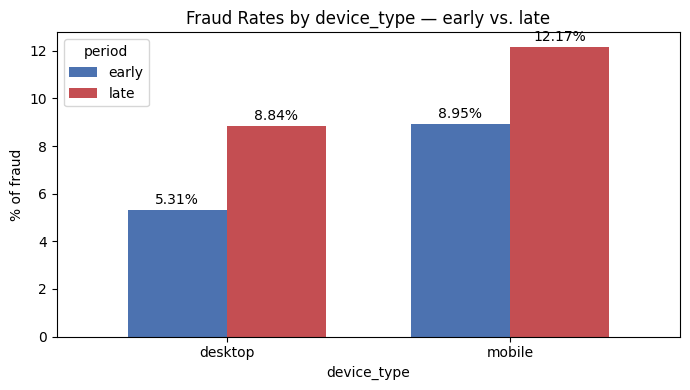

In [0]:
import matplotlib.pyplot as plt
import pandas as pd

df_dev = spark.sql("""
  SELECT
    device_type,
    CASE WHEN transaction_dt < 8000000 THEN 'early' ELSE 'late' END AS period,
    COUNT(*) AS n,
    CAST(100.0 * SUM(is_fraud) / COUNT(*) AS DOUBLE) AS pct_fraud
  FROM fraud.silver.transactions_identity_joined
  WHERE device_type IS NOT NULL
  GROUP BY device_type, period
""").toPandas()

# Diagnostic
print(df_dev)
print(f"\ndtypes :\n{df_dev.dtypes}")

# Explicit cast + pivot
df_dev["pct_fraud"] = pd.to_numeric(df_dev["pct_fraud"], errors="coerce")
pivot = df_dev.pivot(index="device_type", columns="period", values="pct_fraud")
pivot = pivot.apply(pd.to_numeric, errors="coerce")
print(f"\nPivot :\n{pivot}")

# Graph
fig, ax = plt.subplots(figsize=(7, 4))
pivot.plot(kind="bar", ax=ax, color=["#4C72B0", "#C44E52"], width=0.7)
ax.set_ylabel("% of fraud")
ax.set_title("Fraud Rates by device_type — early vs. late")
ax.set_xticklabels(pivot.index, rotation=0)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=2)
plt.tight_layout()
plt.show()

### Device drift (early vs late)

**Scope**: 24.4% of transactions have a device fingerprint (144,233 / 590,540).
Results describe only this fingerprinted subpopulation. Fraud rates are
systematically higher than the 3.5% global baseline — consistent with the fact
that device fingerprint presence correlates with fraud risk (a signal captured
separately in Gold via `is_null_device_type`).

**Results — device_type drift**:
| Device | early | late | Δ pts | Ratio |
|---|---|---|---|---|
| desktop | 5.31 % | 8.84 % | +3.53 | ×1.66 |
| mobile | 8.95 % | 12.17 % | +3.22 | ×1.36 |

**Results — top 5 device_info**:
| Device | early | late | Δ pts | Ratio |
|---|---|---|---|---|
| macOS | 1.55 % | 4.01 % | +2.46 | **×2.58** |
| Trident/7.0 (IE) | 1.04 % | 1.93 % | +0.89 | ×1.87 |
| iOS | 5.44 % | 8.58 % | +3.14 | ×1.58 |
| Windows | 5.62 % | 8.29 % | +2.67 | ×1.48 |
| rv:11.0 (IE11) | 4.19 % | 3.49 % | −0.70 | **×0.83** |

**Results — amount × device (fraud only)**:
| Device | n_fraudes | median | mean | p95 | max |
|---|---|---|---|---|---|
| desktop | 5,554 | 50.00 $ | 81.00 $ | 300 $ | 1,500 $ |
| mobile | 5,657 | 49.48 $ | 96.59 $ | 300 $ | 1,800 $ |

**Key findings**:
1. **Fraud rate surges on both devices over time** (desktop ×1.66, mobile ×1.36).
   Consistent with the global drift (2.19 % → 4.32 %) but amplified in the
   fingerprinted subpopulation.
2. **Mobile is systematically more fraudulent than desktop** (8.95 vs 5.31 early;
   12.17 vs 8.84 late). The ratio is **stable** (~1.4-1.7×) — `device_type` is
   a **non-drifting, stable signal**.
3. **macOS shows the strongest relative drift** (×2.58) despite the lowest
   absolute rate (4.01 % late). Hypothesis: fraudsters migrating to a less-
   scrutinized platform.
4. **`rv:11.0` (IE11) is the only device declining** (−17 %). Rare signal: a
   technology becoming *less* fraudulent. Fraudsters abandoning obsolete vectors.
5. **iOS remains the most fraudulent OS in absolute terms** (8.58 % late),
   consistent with the mobile carding pattern.
6. **Amount distributions are near-identical** across devices (median ~50 $ both).
   Mobile mean is +19 % but driven by outliers (max 1 800 vs 1 500). **No
   meaningful amount × device interaction** to engineer.

**Gold decisions**:
- **`is_mobile` binary feature**: `device_type == "mobile"`. Already in
  categorical feature list — captures the stable mobile/desktop risk differential.
- **`is_null_device_type` flag**: 75.6 % of transactions have no device info;
  absence is itself informative (part of the 168 high-NULL block).
- **No time interaction as feature**: drift is a **model staleness issue**, not
  a feature issue. Handled via **temporal train/valid split** (already decided).
  A model trained on early data must generalize to late data where fraud
  is 2× higher.
- **No amount × device feature**: distributions are effectively identical.

**Production monitoring**:
- Add `device_type` distribution and `device_info` (macOS share) as Evidently AI
  drift signals. Alert if mobile/desktop ratio shifts by > 20 % or if macOS
  share grows by > 5 pts.
- Monitor `rv:11.0` disappearance — a proxy for fraudster tooling changes.

**Limitation**: 24.4 % fingerprint coverage — conclusions apply only to the
fingerprinted subpopulation. The 75.6 % without fingerprint may have different
dynamics.

## II- Building gold data set

In [0]:
%sql
CREATE SCHEMA IF NOT EXISTS fraud.gold
COMMENT 'Modeling-ready datasets: selected features, train/valid/test splits, engineered features';

In [0]:
#  1. Load the lists of selected features
num_features = spark.table("fraud.bronze.eda_features_numeric_final").toPandas()["column_name"].tolist()
cat_features = spark.table("fraud.bronze.eda_features_cat_final").toPandas()["column_name"].tolist()
print(f"{len(num_features)} numeric + {len(cat_features)} categorical = {len(num_features) + len(cat_features)} features")

# 2. Non-feature columns to keep
# transaction_id: reference for debugging + UID for post-processing
# is_fraud : target
# transaction_dt: time axis for the split into Gold
metadata_cols = ["transaction_id", "is_fraud", "transaction_dt"]

#  3. Final list (deduplicate in case transaction_dt is already among the 71)
final_cols = list(dict.fromkeys(metadata_cols + num_features + cat_features))

# 4. Check that all columns exist in Silver
silver_cols = set(spark.table("fraud.silver.transactions_identity_joined").columns)
missing = [c for c in final_cols if c not in silver_cols]
assert not missing, f"Missing columns in silver : {missing}"

# ── 5. Load + Save
df_gold = spark.table("fraud.silver.transactions_identity_joined").select(*final_cols)
df_gold.write.format("delta").mode("overwrite") \
    .saveAsTable("fraud.gold.fraud_dataset_selected")

# ── 6. Verification
result = spark.table("fraud.gold.fraud_dataset_selected")
n_rows = result.count()
n_cols = len(result.columns)

print(f"\n fraud.gold.fraud_dataset_selected")
print(f"Rows    : {n_rows:,}")
print(f"Columns : {n_cols}")
print(f"- {len(num_features)} numeric features")
print(f"- {len(cat_features)} categorical features")
print(f"- {len(metadata_cols)} metadata (transaction_id, is_fraud, transaction_dt)")
print(f"- ({n_cols - len(num_features) - len(cat_features)} after any deduplication)")

71 numeric + 21 categorical = 92 features

 fraud.gold.fraud_dataset_selected
Rows    : 590,540
Columns : 93
- 71 numeric features
- 21 categorical features
- 3 metadata (transaction_id, is_fraud, transaction_dt)
- (1 after any deduplication)
